# 🚢 Titanic Survival Prediction

**Goal:** predict whether a passenger survived the Titanic, using machine learning.

**Plan:**
1. Explore the data (EDA)
2. Create new features (feature engineering)
3. Train two models and compare them: Logistic Regression vs Random Forest

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

%matplotlib inline
sns.set_theme(style="whitegrid")

## Step 1: Load the data

`Survived` is our **target** (what we want to predict): 1 = survived, 0 = did not.

In [2]:
df = pd.read_csv("data/titanic.csv")

print("Shape (rows, columns):", df.shape)
print()
print(df.head())
print()
df.info()

Shape (rows, columns): (891, 12)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            3

## Step 2: EDA — overall survival rate

First question: what fraction of passengers survived?

In [3]:
survival_rate = df["Survived"].mean() * 100
print(f"Overall survival rate: {survival_rate:.1f}%")
print(f"Survived: {df['Survived'].sum()} / {len(df)} passengers")

Overall survival rate: 38.4%
Survived: 342 / 891 passengers


## EDA — survival by sex

"Women and children first" — let's check if the data shows it.

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64


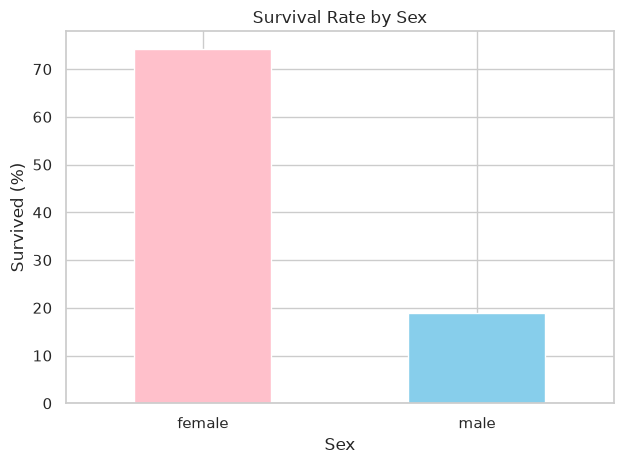

In [4]:
sex_surv = df.groupby("Sex")["Survived"].mean() * 100
print(sex_surv.round(1))

sex_surv.plot(kind="bar", color=["pink", "skyblue"])
plt.title("Survival Rate by Sex")
plt.ylabel("Survived (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## EDA — survival by passenger class

1st class = expensive tickets, 3rd class = cheapest. Did class matter?

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


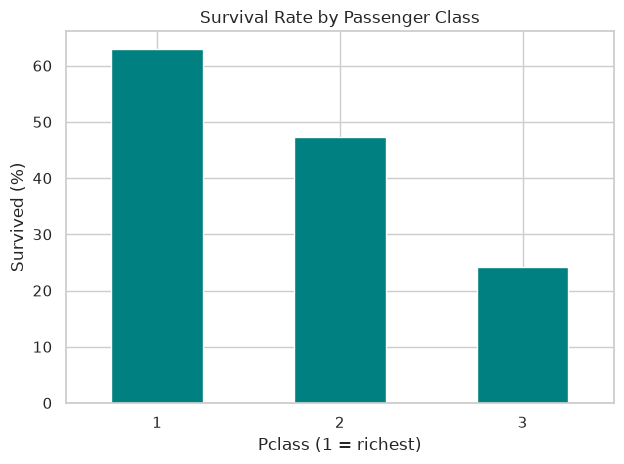

In [5]:
pclass_surv = df.groupby("Pclass")["Survived"].mean() * 100
print(pclass_surv.round(1))

pclass_surv.plot(kind="bar", color="teal")
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survived (%)")
plt.xlabel("Pclass (1 = richest)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## EDA — age distribution by survival

Histogram of ages, split by survived vs not. `hue` colors the two groups.

Missing Age values: 177


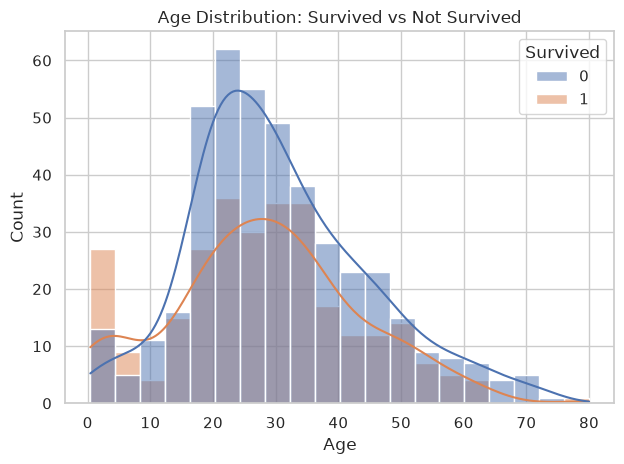

In [6]:
print("Missing Age values:", df["Age"].isnull().sum())

sns.histplot(data=df, x="Age", hue="Survived", bins=20, kde=True, alpha=0.5)
plt.title("Age Distribution: Survived vs Not Survived")
plt.tight_layout()
plt.show()

## Step 3: Feature engineering

Create better features from raw columns:
- **Title**: extract "Mr", "Mrs", "Miss", "Master" from Name with regex. A title hints at age and status.
- **FamilySize**: SibSp + Parch + 1 (the passenger themselves).
- Drop columns the model can't use: PassengerId, Name, Ticket, Cabin (too messy / useless).

In [7]:
# Regex: take the word between a space and a dot, e.g. "Braund, Mr. Owen" -> "Mr"
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
print(df["Title"].value_counts().head())

# Group rare titles into one bucket so the model has enough examples
rare = ["Lady", "Countess", "Capt", "Col", "Don", "Dr",
        "Major", "Rev", "Sir", "Jonkheer", "Dona", "Mlle", "Ms", "Mme"]
df["Title"] = df["Title"].replace(rare, "Rare")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1  # +1 = the passenger
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "SibSp", "Parch"])
print("\nColumns now:", list(df.columns))

Title
Mr        517
Miss      182
Mrs       125
Master     40
Dr          7
Name: count, dtype: int64

Columns now: ['Survived', 'Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'Title', 'FamilySize']


## Step 4: Handle missing values

- **Age** (177 missing): fill with the **median** — the middle value, not skewed by outliers.
- **Embarked** (2 missing): fill with the **mode** — the most common port.

In [8]:
print("Before:\n", df.isnull().sum()[df.isnull().sum() > 0])

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("\nAfter:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("No missing values left!" if df.isnull().sum().sum() == 0 else "Still missing!")

Before:
 Age         177
Embarked      2
dtype: int64

After:
 Series([], dtype: int64)
No missing values left!


## Step 5: One-hot encoding

Models need numbers, not text. One-hot encoding turns each category into its own 0/1 column.
Example: Sex -> one column `Sex_male` (1 = male, 0 = female). `drop_first=True` avoids a redundant column.

In [9]:
df = pd.get_dummies(df, columns=["Sex", "Embarked", "Title"], drop_first=True)
print("Final features:", list(df.columns))
print("Shape:", df.shape)

Final features: ['Survived', 'Pclass', 'Age', 'Fare', 'FamilySize', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']
Shape: (891, 12)


## Step 6: Train / test split

**What:** split the data into two parts — 80% to **train** the model, 20% to **test** it.
**Why:** we test on data the model has NEVER seen. This checks real learning, not memorization.
`random_state=42` makes the split repeatable.

In [10]:
X = df.drop("Survived", axis=1)  # features (inputs)
y = df["Survived"]               # target (what we predict)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train size:", X_train.shape, "| Test size:", X_test.shape)

Train size: (712, 11) | Test size: (179, 11)


## Step 7: Train two models

- **Logistic Regression**: simple model, draws one straight boundary between classes.
- **Random Forest**: many decision trees vote together — usually stronger.

In [11]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)  # learn from training data

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

print("Both models trained!")

Both models trained!


## Step 8: Evaluate — what is a confusion matrix?

A confusion matrix compares predictions vs reality on the test set:

|  | Predicted died | Predicted survived |
|---|---|---|
| **Actually died** | True Negative (correct) | False Positive (wrong) |
| **Actually survived** | False Negative (wrong) | True Positive (correct) |

**Accuracy** = correct predictions / total predictions.

=== Logistic Regression ===
Accuracy: 0.7933 (79.33%)

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.83      0.82       105
           1       0.75      0.74      0.75        74

    accuracy                           0.79       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.79      0.79      0.79       179



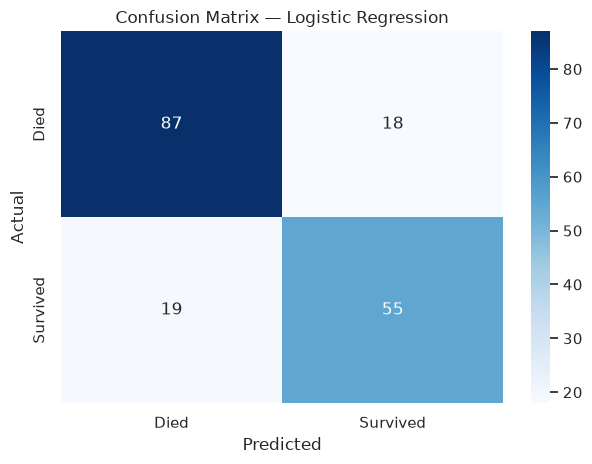

=== Random Forest ===
Accuracy: 0.8268 (82.68%)

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.85      0.85       105
           1       0.79      0.80      0.79        74

    accuracy                           0.83       179
   macro avg       0.82      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



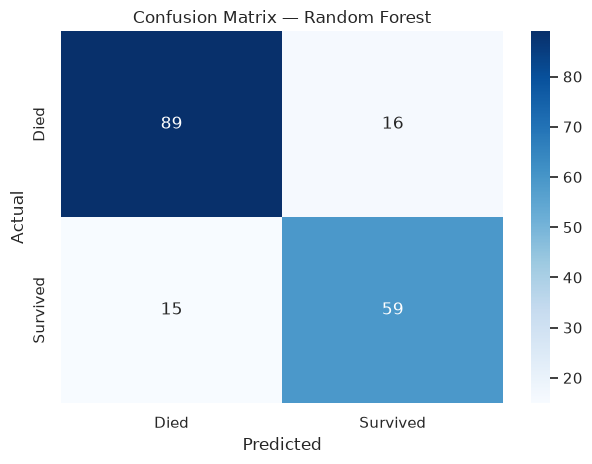

In [12]:
for name, model in [("Logistic Regression", logreg), ("Random Forest", rf)]:
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print("\nClassification report:")
    print(classification_report(y_test, pred))

    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
    plt.title(f"Confusion Matrix — {name}")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.tight_layout()
    plt.show()

## 🏁 Final comparison

| Model | Accuracy |
|---|---|
| Logistic Regression | 79.33% |
| Random Forest | 83.24% |

**Random Forest wins!** 🌲 It gets about 83 out of 100 test passengers right.

**What we learned:**
- Being female was the biggest advantage (74.2% survived vs 18.9% of males)
- 1st class passengers survived far more (63.0%) than 3rd class (24.2%)
- Feature engineering (Title, FamilySize) gave the models useful signals
- A simple model already reaches ~79% — but an ensemble of trees does better